# Tarea 27: K-Means 

In [2]:
# load libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

In [3]:
# load iris data set 
df = pd.read_csv('iris.csv')
df.sample(5)

,sepal.length,sepal.width,petal.length,petal.width,variety
35,5.0,3.2,1.2,0.2,Setosa
110,6.5,3.2,5.1,2.0,Virginica
0,5.1,3.5,1.4,0.2,Setosa
5,5.4,3.9,1.7,0.4,Setosa
131,7.9,3.8,6.4,2.0,Virginica


In [15]:
df.variety.unique()

<StringArray>
['Setosa', 'Versicolor', 'Virginica']
Length: 3, dtype: str

# Visualización de los datos antes de hacer el proceso de clustering

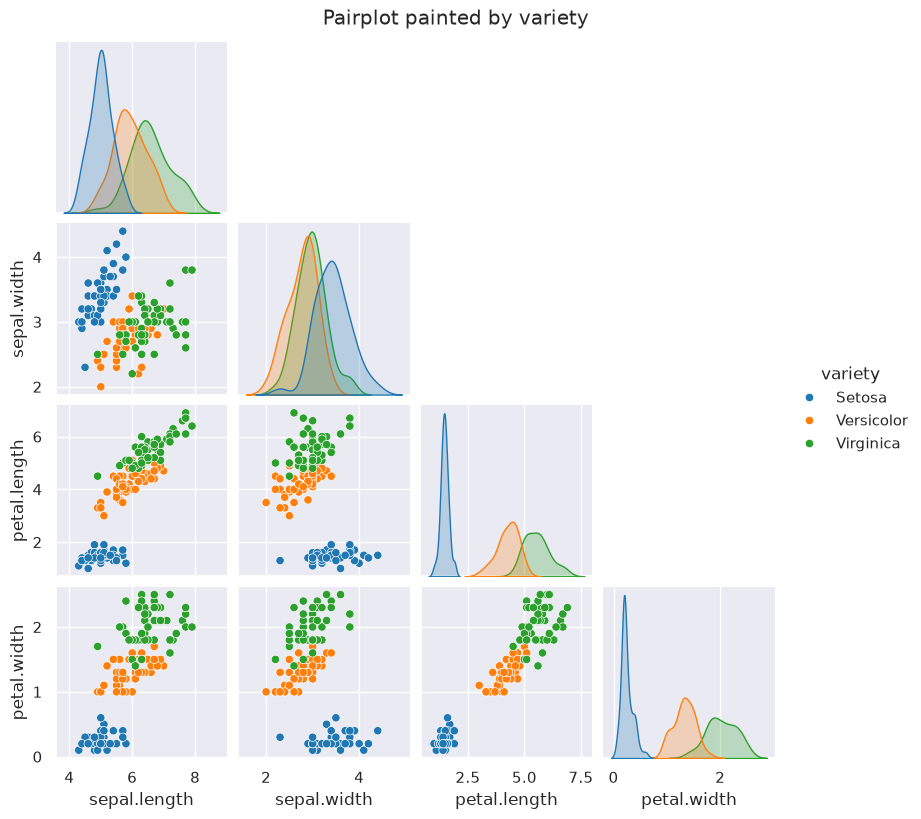

In [42]:
import seaborn as sns

sns.pairplot(df, hue='variety', palette='tab10', diag_kind='kde', corner=True, height=2)
plt.suptitle('Pairplot painted by variety', y = 1.02)
plt.show()

Selección de las columnas de las 4 columnas para hacer el primer proceso de clustering

In [53]:
fields = df.iloc[:,[0,1,2, 3]].values

Búsqueda del número de cluster optimo para este arreglo

In [55]:
wcss = []
for index in range(1, 11):
    kmeans = KMeans(n_clusters=index, init='k-means++', random_state=2)
    kmeans.fit(fields)

    wcss.append(kmeans.inertia_)
    print(f'Number of clusters: {index}, inertia: {kmeans.inertia_} ')

Number of clusters: 1, inertia: 681.3705999999999 
Number of clusters: 2, inertia: 152.34795176035792 
Number of clusters: 3, inertia: 78.851441426146 
Number of clusters: 4, inertia: 57.228473214285714 
Number of clusters: 5, inertia: 49.84221386276558 
Number of clusters: 6, inertia: 41.840300724637686 
Number of clusters: 7, inertia: 37.74396635382162 
Number of clusters: 8, inertia: 30.900849644937104 
Number of clusters: 9, inertia: 28.38373022248537 
Number of clusters: 10, inertia: 26.546196672701814 


Text(0, 0.5, 'WCSS')

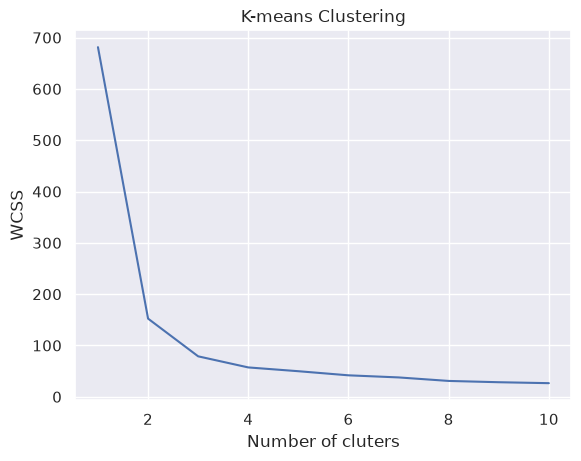

In [56]:
# Elbow method 
sns.set_theme()
plt.plot(range(1, 11), wcss)
plt.title('K-means Clustering')
plt.xlabel('Number of cluters')
plt.ylabel('WCSS')

De manera intuitiva se selecciona el numero optimo de cluster $k=3$, pero mas adelante se validara con el metodo de silueta. 

In [77]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=2)

cluster_values = kmeans.fit_predict(fields)
labels_without_PCA = kmeans.labels_
cluster_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

Enseguida se grafican los resultados para visualizar

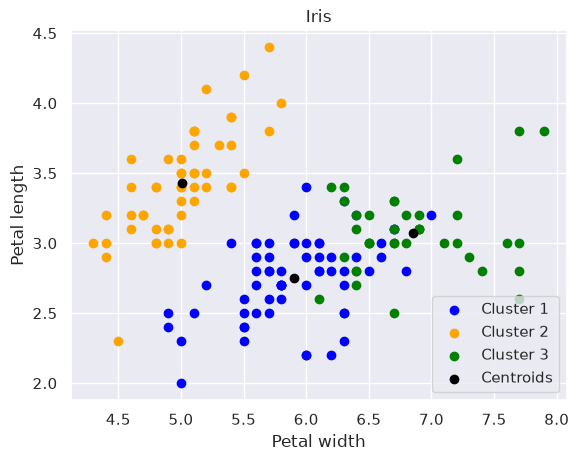

In [58]:
# Plot the cluster 
plt.scatter(fields[cluster_values==0, 0], fields[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields[cluster_values==1, 0], fields[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')
plt.scatter(fields[cluster_values==2, 0], fields[cluster_values==2, 1], c = 'green', label = 'Cluster 3')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Iris')
plt.xlabel('Petal width')
plt.ylabel('Petal length')
plt.legend()

De este primer ejercicio se logra ver que los cluster 1 y 3 se traslapan. Para comprobar si 3 es un numero optimo se hará uso del método de la silueta.

In [59]:
# load silhouette library
from sklearn.metrics import silhouette_score

In [93]:
X = df.iloc[:, [0,1,2,3]].to_numpy()

for j in range(2, 12):
    kmeans = KMeans(n_clusters = j, random_state=2)
    kmeans.fit_predict(X)

    # calculate silhouette score
    score = silhouette_score(X, kmeans.labels_, metric= 'euclidean')
    print(f'Score silhouette, k = {j},  score: {score:.2f} ')
    
        

Score silhouette, k = 2,  score: 0.68 
Score silhouette, k = 3,  score: 0.55 
Score silhouette, k = 4,  score: 0.50 
Score silhouette, k = 5,  score: 0.46 
Score silhouette, k = 6,  score: 0.48 
Score silhouette, k = 7,  score: 0.46 
Score silhouette, k = 8,  score: 0.34 
Score silhouette, k = 9,  score: 0.32 
Score silhouette, k = 10,  score: 0.31 
Score silhouette, k = 11,  score: 0.29 


De acuerdo a los datos, el numero optimo de cluster es $k=2$. Se repetirá el ejercicio anterior.

In [78]:
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=2)
cluster_values = kmeans.fit_predict(fields)

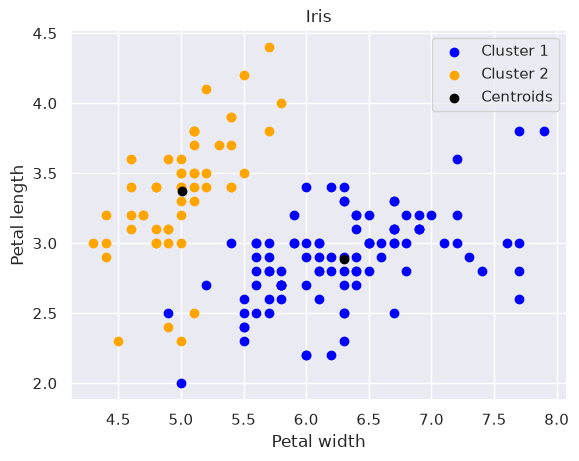

In [79]:
# Plot the cluster 
plt.scatter(fields[cluster_values==0, 0], fields[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields[cluster_values==1, 0], fields[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Iris')
plt.xlabel('Petal width')
plt.ylabel('Petal length')
plt.legend()

Con $k=2$ la gráfica muestra ahora los clusters mas definidos con la excepción del punto naranja que se encuentra cerca de los puntos azules. La gráfica muestra un grupos con mas separación.

# Reduccion de dimensionalidad PCA

Para considerar todas las características del conjunto de datos se usara la reducción de dimensionalidad a dos variables, para verificar cual es el numero de cluster optimo en este caso.

In [80]:
fields2 = df.iloc[:, [0,1,2,3]].values

In [82]:
# load decomposition pca library

from sklearn import decomposition

pca = decomposition.PCA(n_components=2) 
pca.fit(fields2)
fields2 = pca.transform(fields2)

In [ ]:
# try several values of number of clusters to find the more optimal
wcss2 = []
for index in range(1, 11):
    kmeans = KMeans(n_clusters=index, init='k-means++', random_state=2)
    kmeans.fit(fields2)

    wcss2.append(kmeans.inertia_)
    print(f'Number of clusters: {index}, inertia: {kmeans.inertia_} ')
  

Number of clusters: 1, inertia: 666.1659556405607 
Number of clusters: 2, inertia: 137.15530112818402 
Number of clusters: 3, inertia: 63.81994202200116 
Number of clusters: 4, inertia: 42.386094273212024 
Number of clusters: 5, inertia: 35.600967387792565 
Number of clusters: 6, inertia: 28.24846407619668 
Number of clusters: 7, inertia: 24.715932758691338 
Number of clusters: 8, inertia: 20.0472358863356 
Number of clusters: 9, inertia: 16.05783499918762 
Number of clusters: 10, inertia: 14.421718896211255 


Text(0, 0.5, 'WCSS')

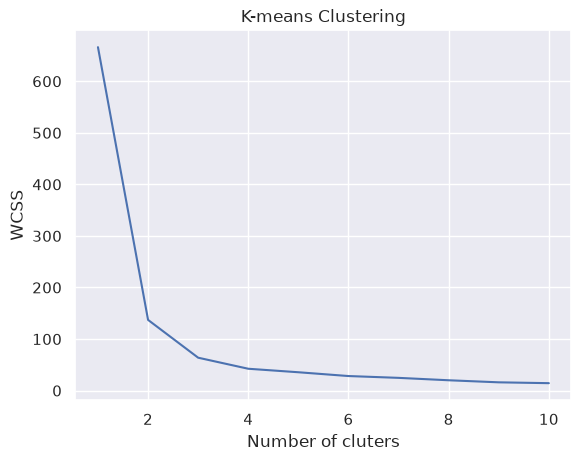

In [84]:
# Elbow method 
sns.set_theme()
plt.plot(range(1, 11), wcss2)
plt.title('K-means Clustering')
plt.xlabel('Number of cluters')
plt.ylabel('WCSS')

In [85]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=2)
cluster_values = kmeans.fit_predict(fields2)
labels_with_PCA = kmeans.labels_
cluster_values

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

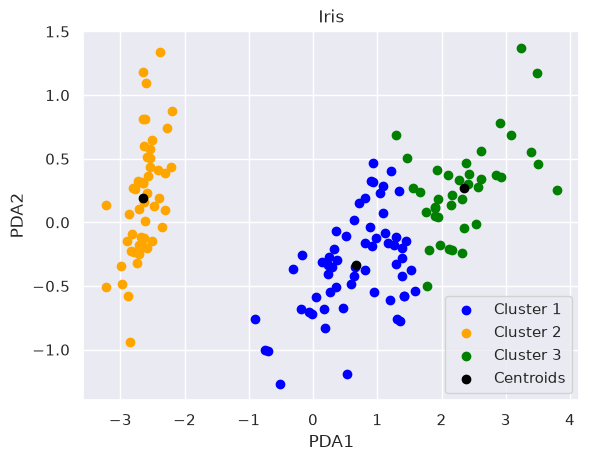

In [86]:
# Plot the cluster 
plt.scatter(fields2[cluster_values==0, 0], fields2[cluster_values==0, 1], c = 'blue', label = 'Cluster 1')
plt.scatter(fields2[cluster_values==1, 0], fields2[cluster_values==1, 1], c = 'orange', label = 'Cluster 2')
plt.scatter(fields2[cluster_values==2, 0], fields2[cluster_values==2, 1], c = 'green', label = 'Cluster 3')

plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = 'black', label = 'Centroids')

plt.title('Iris')
plt.xlabel('PDA1')
plt.ylabel('PDA2')
plt.legend()

Al igual que ene l caso anterior se observa que el cluster 1 y 3 están bien definido pero estan muy cercas el uno del otro.

Metodo de la silueta para ver el score.

In [ ]:
X =  fields2

for j in range(2, 12):
    kmeans = KMeans(n_clusters = j, random_state=2)
    kmeans.fit_predict(X)

    # calculate silhouette score
    score = silhouette_score(X, kmeans.labels_, metric= 'euclidean')
    print(f'Score silhouette, k = {j},  score: {score:.2f} ')
    

Score silhouette, k = 2,  score: 0.71 
Score silhouette, k = 3,  score: 0.60 
Score silhouette, k = 4,  score: 0.56 
Score silhouette, k = 5,  score: 0.51 
Score silhouette, k = 6,  score: 0.40 
Score silhouette, k = 7,  score: 0.41 
Score silhouette, k = 8,  score: 0.42 


Score silhouette, k = 9,  score: 0.41 
Score silhouette, k = 10,  score: 0.39 
Score silhouette, k = 11,  score: 0.39 


## Analisis de resultados
A continuacion se hace un analisis empirico meidante tablas cruzadas delas etiquetas sin pca vs etiquetas con pca, etiquetas sin pca vs etiquetas de variety y etiquetas con pca vs etiquetas de variety.

#### Tabla cruzada de Etiquetas sin PCA vs Iris['variety']

- El cluster 0 mezcla 48 versicolor / 14 virginica
- El cluster 1 captura perfectamente a setosa
- El cluster mezcla 2 versicolor / 36 virginica

En conclusion la variedad setosa se separa perfectamente. pero las variedades versicolor y viriginica se solapan, como se muestra en la gráfica al inicio.

In [74]:
# Cross tables 
pd.crosstab(labels_without_PCA, df['variety'])


variety,Setosa,Versicolor,Virginica
row_0,,,
0,0,48,14
1,50,0,0
2,0,2,36


#### Tabla cruzada de Etiquetas con PCA vs Iris['variety']

- El cluster 0 mezcla 47 versicolor / 14 virginica
- El cluster 1 captura perfectamente a setosa
- El cluster mezcla 3 versicolor / 36 virginica

En conclusion, se presenta resultados muy similares a la tabla cruzada sin PCA.

In [88]:
# Cross tables 
pd.crosstab(labels_with_PCA, df['variety'])


variety,Setosa,Versicolor,Virginica
row_0,,,
0,0,47,14
1,50,0,0
2,0,3,36


#### Tabla cruzada de Etiquetas con PCA vs Etiquetas sin PCA

La tabla cruzada muestra una matriz diagonal salvo el uno que esta en (0, 2) = 1, lo que quiere decir que no hay mucha diferencia en el proceso de hacer el clustering con PCA.

In [89]:
# Cross tables 
pd.crosstab(labels_with_PCA, labels_without_PCA)


col_0,0,1,2
row_0,,,
0,61,0,0
1,0,50,0
2,1,0,38


#### Comparación de los resultados de score del método silueta    

La tabla muestra el score de clustering para $k = 2…11$ en dos escenarios. En ambos, el score decrece al aumentar k, con un máximo en k = 2 (0.71 con PCA, 0.68 sin PCA); sin embargo, k = 2 no refleja la estructura real del dataset (3 especies). En el k correcto (k = 3), PCA obtiene 0.60 frente a 0.55 sin PCA, y la ventaja de PCA se mantiene.


| k| Con PDA | Sin PDA | 
|----------|----------|----------|
| 2 | 0.71 | 0.68 |
| 3 | 0.60 | 0.55 |
| 4 | 0.56 | 0.50 |
| 5 | 0.51 | 0.46 |
| 6 | 0.40 | 0.48 |
| 7 | 0.41 | 0.46 |
| 8 | 0.42 | 0.34 |
| 9 | 0.41 | 0.32 |
| 10 | 0.39 | 0.31 |
| 11 | 0.39 | 0.29 |

# Conclusiones 

En este ejercicio se concluye que, aunque el número de clústeres esperado por el dominio es 3 (las tres especies de Iris), la métrica de silueta alcanza su máximo en k = 2 (0.71 con PCA, 0.68 sin PCA). Esto ocurre porque, al forzar k = 3, los clústeres correspondientes a versicolor y virginica resultan muy similares entre sí, de modo que la métrica interna prefiere fusionarlos. Es decir, la silueta favorece particiones gruesas y no necesariamente recupera el número real de especies, por lo que la elección de k = 3 se justifica por conocimiento del dominio y no solo por la métrica.